In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = ((0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) +
               np.random.normal(0, 5, n))

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan   # Missing values
df.loc[99, 'study_hours'] = 50        # Outlier
df.loc[98, 'attendance'] = -10        # Impossible value

print(df)
df.to_csv('student_data.csv', index=False)   # save the raw (dirty) data

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


In [4]:
# Chart styling used for every figure in this notebook
SURFACE, INK, INK_2, SERIES = '#fcfcfb', '#0b0b0b', '#52514e', '#2a78d6'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': '#c9c8c3', 'axes.labelcolor': INK_2,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'font.size': 11, 'axes.titlesize': 13,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})

In [5]:
raw = df.copy()         
raw.info()
print()
print('Missing values per column:')
print(raw.isna().sum())
print()
print(raw.describe().round(2))

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   study_hours    94 non-null     float64
 1   attendance     100 non-null    float64
 2   previous_mark  100 non-null    float64
 3   final_score    100 non-null    float64
dtypes: float64(4)
memory usage: 3.3 KB

Missing values per column:
study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64

       study_hours  attendance  previous_mark  final_score
count        94.00      100.00         100.00       100.00
mean          5.22       84.27          70.97        42.69
std           5.01       13.48          16.26         6.09
min          -0.24      -10.00          21.38        29.16
25%           3.73       76.83          60.17        38.19
50%           4.81       85.84          71.47        42.76
75%           5.74       90.38          80.57        46.69
max          5

In [6]:
sh = raw['study_hours']
q1, q3 = sh.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

others = sh.drop(99).dropna()
z_50 = (50 - others.mean()) / others.std()

print(f'Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}')
print(f'Upper IQR fence = {upper_fence:.2f} hours')
print(f'Highest value among the other students = {others.max():.2f} hours')
print(f'50 hours sits {z_50:.1f} standard deviations above the other students\' mean')
print()
print('Row 99:')
print(raw.loc[99])
print(f"Row 99's final_score is higher than {(raw['final_score'] < raw.loc[99, 'final_score']).mean():.0%} of students")

Q1 = 3.73, Q3 = 5.74, IQR = 2.01
Upper IQR fence = 8.76 hours
Highest value among the other students = 8.70 hours
50 hours sits 24.6 standard deviations above the other students' mean

Row 99:
study_hours      50.000000
attendance       73.570297
previous_mark    79.444433
final_score      46.414470
Name: 99, dtype: float64
Row 99's final_score is higher than 71% of students


In [7]:
clean = raw.copy()

# 1. Outlier and impossible value -> missing
clean.loc[clean['study_hours'] > upper_fence, 'study_hours'] = np.nan
clean.loc[clean['attendance'] < 0, 'attendance'] = np.nan

# 2. Clip values that cross a hard limit
print('Values outside valid ranges before clipping:')
print(f"  attendance > 100:     {(clean['attendance'] > 100).sum()}")
print(f"  previous_mark > 100:  {(clean['previous_mark'] > 100).sum()}")
print(f"  study_hours < 0:      {(clean['study_hours'] < 0).sum()}")
clean['attendance'] = clean['attendance'].clip(upper=100)
clean['previous_mark'] = clean['previous_mark'].clip(upper=100)
clean['study_hours'] = clean['study_hours'].clip(lower=0)

# 3. Drop rows with any missing value (rows 0-5, 98, 99)
dropped = clean.index[clean.isna().any(axis=1)].tolist()
clean = clean.dropna()

print(f'\nRows dropped: {dropped}')
print(f'Rows remaining: {len(clean)}')
df = clean   # use the cleaned data from here on

Values outside valid ranges before clipping:
  attendance > 100:     7
  previous_mark > 100:  5
  study_hours < 0:      1

Rows dropped: [0, 1, 2, 3, 4, 5, 98, 99]
Rows remaining: 92


In [8]:
features = ['study_hours', 'attendance', 'previous_mark']
target = 'final_score'

X = df[features]
y = df[target]

print('Feature matrix X shape:', X.shape)
print('Target vector y shape: ', y.shape)
print()
print(df.dtypes)

Feature matrix X shape: (92, 3)
Target vector y shape:  (92,)

study_hours      float64
attendance       float64
previous_mark    float64
final_score      float64
dtype: object


In [9]:
summary = df.agg(['mean', 'median', 'std']).T.round(2)
summary

,mean,median,std
study_hours,4.74,4.70,1.84
attendance,85.22,86.74,8.77
previous_mark,70.28,71.01,15.44
final_score,42.72,42.76,6.20


In [10]:
# For comparison: the same statistics on the raw data before cleaning
raw.agg(['mean', 'median', 'std']).T.round(2)


,mean,median,std
study_hours,5.22,4.81,5.01
attendance,84.27,85.84,13.48
previous_mark,70.97,71.47,16.26
final_score,42.69,42.76,6.09


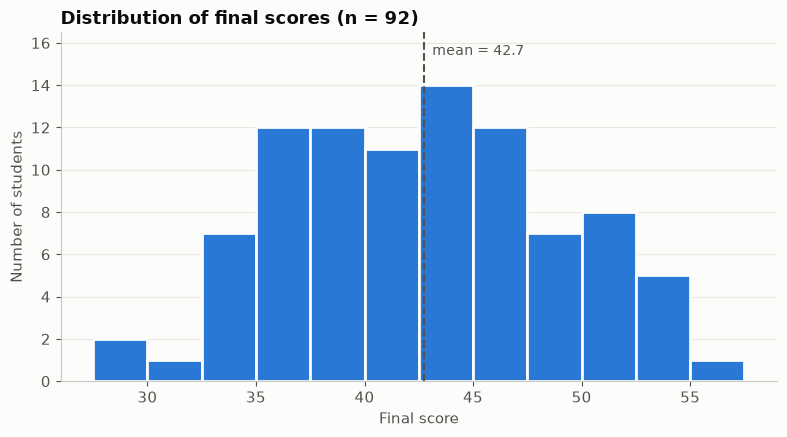

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(27.5, 60, 2.5)
ax.hist(df['final_score'], bins=bins, color=SERIES, edgecolor=SURFACE, linewidth=2)

mean_fs = df['final_score'].mean()
ax.set_ylim(0, 16.5)
ax.axvline(mean_fs, color=INK_2, linestyle='--', linewidth=1.5)
ax.text(mean_fs + 0.4, 15.6, f'mean = {mean_fs:.1f}', color=INK_2, fontsize=10, va='center')

ax.set_title('Distribution of final scores (n = 92)')
ax.set_xlabel('Final score')
ax.set_ylabel('Number of students')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

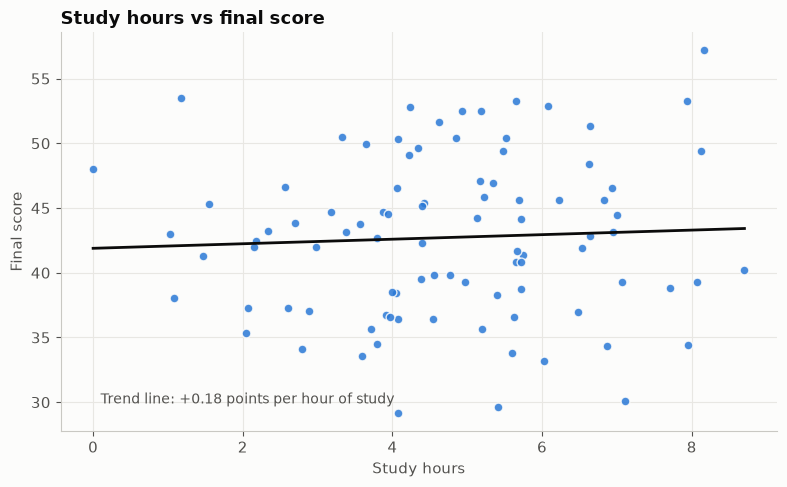

Line of best fit: final_score = 0.18 × study_hours + 41.89


In [12]:
slope, intercept = np.polyfit(df['study_hours'], df['final_score'], 1)
xs = np.linspace(df['study_hours'].min(), df['study_hours'].max(), 100)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df['study_hours'], df['final_score'], s=40, color=SERIES, alpha=0.85,
           edgecolor=SURFACE, linewidth=1)
ax.plot(xs, slope * xs + intercept, color=INK, linewidth=2)
ax.text(0.1, 30.2, f'Trend line: +{slope:.2f} points per hour of study',
        color=INK_2, fontsize=10, va='center')

ax.set_title('Study hours vs final score')
ax.set_xlabel('Study hours')
ax.set_ylabel('Final score')
plt.tight_layout()
plt.show()

print(f'Line of best fit: final_score = {slope:.2f} × study_hours + {intercept:.2f}')

In [13]:
r_numpy = np.corrcoef(df['study_hours'], df['final_score'])[0, 1]
r, p_value = pearsonr(df['study_hours'], df['final_score'])

print(f'Pearson r (NumPy): {r_numpy:.3f}')
print(f'Pearson r (SciPy): {r:.3f}   p-value = {p_value:.3f}')
print(f'r squared:         {r**2:.4f}  -> study hours explain {r**2:.1%} of the variation in final score')

Pearson r (NumPy): 0.052
Pearson r (SciPy): 0.052   p-value = 0.620
r squared:         0.0027  -> study hours explain 0.3% of the variation in final score


In [14]:
# Context: how every feature correlates with the final score
df.corr().round(3)

,study_hours,attendance,previous_mark,final_score
study_hours,1.000,-0.084,0.160,0.052
attendance,-0.084,1.000,-0.021,0.435
previous_mark,0.160,-0.021,1.000,0.538
final_score,0.052,0.435,0.538,1.000


In [15]:
student = df.loc[7]
x = student[features].to_numpy()          # feature vector (target excluded)
w = np.array([0.5, 0.2, 0.4])             # weights for [study_hours, attendance, previous_mark]
b = 5                                     # bias

y_hat = np.dot(w, x) + b

print('x =', np.round(x, 2), ' (study_hours, attendance, previous_mark)')
print('w =', w)
print('b =', b)
print()
print('Contribution of each feature (w * x):', np.round(w * x, 2))
print(f'y_hat = w · x + b = {np.dot(w, x):.2f} + {b} = {y_hat:.2f}')
print(f"Actual final_score for this student: {student['final_score']:.2f}")

x = [ 6.53 86.75 77.71]  (study_hours, attendance, previous_mark)
w = [0.5 0.2 0.4]
b = 5

Contribution of each feature (w * x): [ 3.27 17.35 31.08]
y_hat = w · x + b = 51.70 + 5 = 56.70
Actual final_score for this student: 41.87


In [16]:
for col in ['study_hours', 'previous_mark']:
    df[col + '_z'] = (df[col] - df[col].mean()) / df[col].std()

df[['study_hours', 'study_hours_z', 'previous_mark', 'previous_mark_z']].head()

,study_hours,study_hours_z,previous_mark,previous_mark_z
6,8.158426,1.855419,77.725529,0.482100
7,6.534869,0.974965,77.706789,0.480886
8,4.061051,-0.366587,77.725715,0.482112
9,6.085120,0.731066,100.000000,1.925115
10,4.073165,-0.360018,78.563358,0.536377


In [17]:
# Check: each standardized column should now have mean 0 and standard deviation 1
check = df[['study_hours_z', 'previous_mark_z']].agg(['mean', 'std', 'min', 'max']).round(3)
check.loc['mean'] = check.loc['mean'].abs()   # tidy -0.0 display
check

,study_hours_z,previous_mark_z
mean,0.000,0.000
std,1.000,1.000
min,-2.569,-3.168
max,2.152,1.925


In [18]:
ranges = df[['study_hours', 'previous_mark']].agg(['min', 'max', 'std']).T
ranges['range'] = ranges['max'] - ranges['min']
print(ranges.round(2))

var_sh = df['study_hours'].var()
var_pm = df['previous_mark'].var()
print(f'\nShare of the average squared distance between two students due to previous_mark:')
print(f'  unscaled: {var_pm / (var_sh + var_pm):.1%}')
print(f'  scaled:   50.0%  (both features have variance 1 after standardizing)')

                 min    max    std  range
study_hours     0.00    8.7   1.84   8.70
previous_mark  21.38  100.0  15.44  78.62

Share of the average squared distance between two students due to previous_mark:
  unscaled: 98.6%
  scaled:   50.0%  (both features have variance 1 after standardizing)


In [21]:
# A concrete example: which student is "closest" to student P?
sd_sh, sd_pm = df['study_hours'].std(), df['previous_mark'].std()

P = np.array([4.0, 70.0])   # 4 study hours, previous mark 70
Q = np.array([8.0, 70.0])   # same mark, but 4 more hours of study
R = np.array([4.0, 75.0])   # same hours, but 5 more marks

def dist(a, b):
    return np.linalg.norm(a - b)

scale = np.array([sd_sh, sd_pm])
print('Unscaled distance  P-Q: {:.2f}   P-R: {:.2f}'.format(dist(P, Q), dist(P, R)))
print('Scaled distance    P-Q: {:.2f}   P-R: {:.2f}'.format(dist(P / scale, Q / scale), dist(P / scale, R / scale)))

Unscaled distance  P-Q: 4.00   P-R: 5.00
Scaled distance    P-Q: 2.17   P-R: 0.32
